In [142]:
# ==== Cohort Binder (DO NOT MODIFY) ==== 
import hashlib, json, random, numpy as np, datetime, os 
import matplotlib.pyplot as plt 
STUDENT_NAME = input("Enter your full name: ").strip() 
ROLL_NO      = input("Enter your college roll number: ").strip() 
SALT         = "AIML_Capstone_2026"   # fixed by instructor 
sig_str = json.dumps({"n": STUDENT_NAME, "r": ROLL_NO, "s": SALT}) 
STUDENT_SIG = hashlib.sha256(sig_str.encode()).hexdigest()[:12] 
SEED = int(STUDENT_SIG[:8], 16) % (2**31-1) 
random.seed(SEED) 
np.random.seed(SEED) 
TODAY = datetime.date.today().isoformat() 
OUT_PREFIX = f"AIML_{STUDENT_SIG}_{TODAY}" 
os.makedirs("out", exist_ok=True) 
def stamp_plot(title): 
    plt.title(f"{title}\nSIG:{STUDENT_SIG} DATE:{TODAY}") 
print(f"Student: {STUDENT_NAME} | College Roll No: {ROLL_NO}") 
print(f"Signature: {STUDENT_SIG} | Seed: {SEED}") 
print(f"Output prefix: out/{OUT_PREFIX}_*") 

Student: GADAMSETTY NAGA MANIKANTA THARUN | College Roll No: 24UCS123
Signature: c5c95b70276e | Seed: 1170824049
Output prefix: out/AIML_c5c95b70276e_2026-07-11_*


In [2]:
#importing necessary libraries
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
news_data=pd.read_json("Dataset File/News_Category_Dataset_v3.json",lines=True)
news_data.head()

,link,headline,category,short_description,authors,date
0,https://www.huffpost.com/entry/covid-boosters-...,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,Health experts said it is too early to predict...,"Carla K. Johnson, AP",2022-09-23
1,https://www.huffpost.com/entry/american-airlin...,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,He was subdued by passengers and crew when he ...,Mary Papenfuss,2022-09-23
2,https://www.huffpost.com/entry/funniest-tweets...,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,"""Until you have a dog you don't understand wha...",Elyse Wanshel,2022-09-23
3,https://www.huffpost.com/entry/funniest-parent...,The Funniest Tweets From Parents This Week (Se...,PARENTING,"""Accidentally put grown-up toothpaste on my to...",Caroline Bologna,2022-09-23
4,https://www.huffpost.com/entry/amy-cooper-lose...,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,Amy Cooper accused investment firm Franklin Te...,Nina Golgowski,2022-09-22


In [6]:
news_data.info()
news_data.shape

<class 'pandas.DataFrame'>
RangeIndex: 209527 entries, 0 to 209526
Data columns (total 6 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   link               209527 non-null  str           
 1   headline           209527 non-null  str           
 2   category           209527 non-null  str           
 3   short_description  209527 non-null  str           
 4   authors            209527 non-null  str           
 5   date               209527 non-null  datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 9.6 MB


(209527, 6)

In [ ]:
#there are no missing values in the dataset 
news_data.duplicated().sum()

np.int64(13)

In [ ]:
#There are duplicate rows so let us remove them
news_data.drop_duplicates(inplace=True)

In [ ]:
#now after dropping some rows we need to reset the index because it may lead to unordered data representation
news_data.reset_index(drop=True, inplace=True)

In [10]:
news_data.duplicated().sum()

np.int64(0)

In [11]:
#Now we can see there are no duplicate rows 
#And as we are only classifying our data based heaadlines all other columns are insignificant for us so let us drop them
news_data=news_data[["headline","category"]]
news_data.head()

,headline,category
0,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS
1,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS
2,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY
3,The Funniest Tweets From Parents This Week (Se...,PARENTING
4,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS


In [14]:
#Now let us check how many categories of news is present
news_data["category"].value_counts()

category
POLITICS          35601
WELLNESS          17942
ENTERTAINMENT     17362
TRAVEL             9900
STYLE & BEAUTY     9811
PARENTING          8791
HEALTHY LIVING     6694
QUEER VOICES       6347
FOOD & DRINK       6340
BUSINESS           5992
COMEDY             5400
SPORTS             5077
BLACK VOICES       4583
HOME & LIVING      4320
PARENTS            3955
THE WORLDPOST      3664
WEDDINGS           3653
WOMEN              3571
CRIME              3562
IMPACT             3484
DIVORCE            3426
WORLD NEWS         3299
MEDIA              2944
WEIRD NEWS         2777
GREEN              2622
WORLDPOST          2579
RELIGION           2577
STYLE              2254
SCIENCE            2206
TECH               2100
TASTE              2096
MONEY              1756
ARTS               1509
ENVIRONMENT        1443
FIFTY              1401
GOOD NEWS          1398
U.S. NEWS          1377
ARTS & CULTURE     1339
COLLEGE            1144
LATINO VOICES      1130
CULTURE & ARTS     1074
EDUCATI

In [ ]:
#there 42 different categories present in the headlines
news_data['category'].nunique()

42

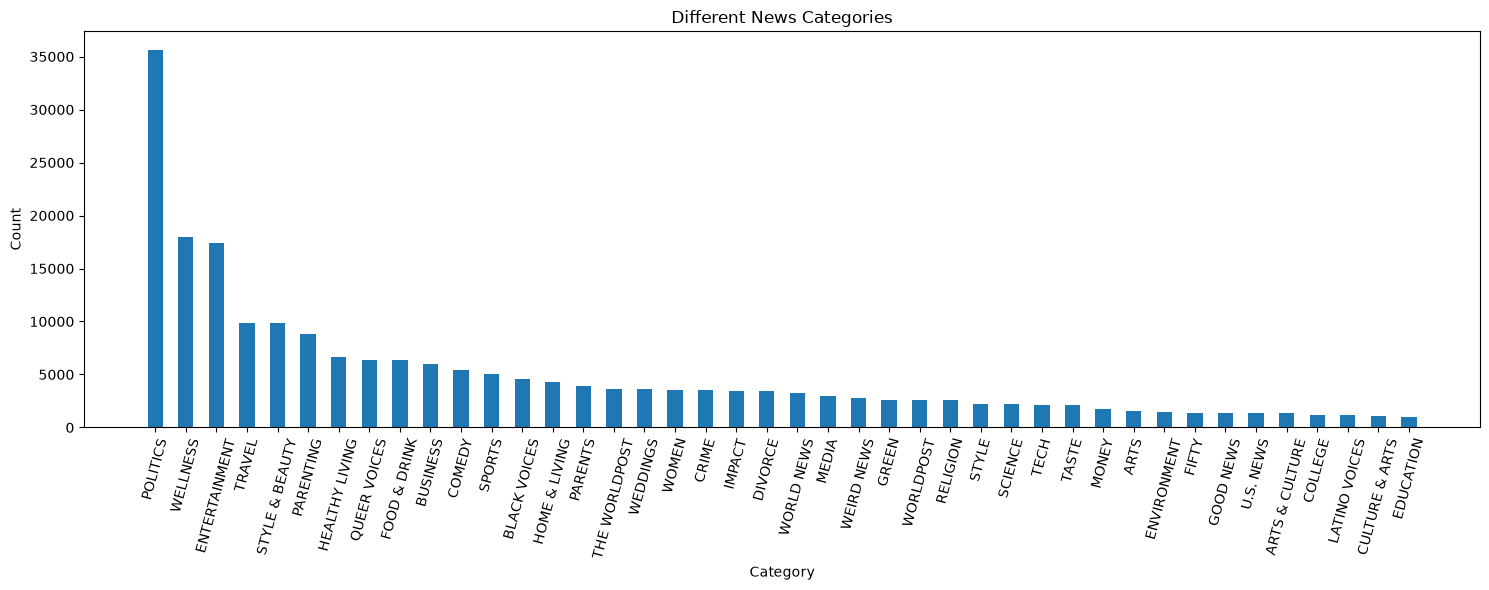

In [61]:
#Bar graph of different classes present and their distribution
category_counts = news_data["category"].value_counts()
plt.figure(figsize=(15, 6))
plt.bar(
    category_counts.index,
    category_counts.values,
    width=0.5      
)
plt.xticks(rotation=75)
plt.xlabel("Category")
plt.ylabel("Count")
plt.title("Different News Categories")
plt.tight_layout()
plt.show()

In [28]:
#from above graph clearly we can see there is class imbalance so we need to startify the data while splitting so there are 
#seperated by equal composition
news_data["headline_length"] = news_data["headline"].apply(lambda x: len(x.split()))

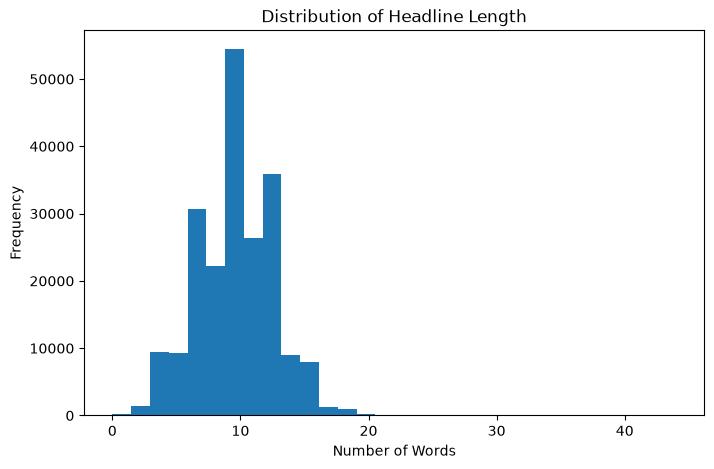

In [ ]:
#we created a new column headline length which says us how many words does a headline is divided into 
plt.figure(figsize=(8,5))
plt.hist(news_data["headline_length"], bins=30)
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.title("Distribution of Headline Length")
plt.show()

In [ ]:
#we need to convert words into tokens before sending it into BERT model so we use a bert base uncased tokenizer 
#then we created a new column token length which is useful for determining the max length of the context window for token id's
#here lambda is a nameless function which takes arguments : expressions ,apply is used for a column or row which is simply take this
#row or column and apply to it
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

news_data["token_length"] = news_data["headline"].apply(
    lambda x: len(tokenizer.encode(x, add_special_tokens=True))
)

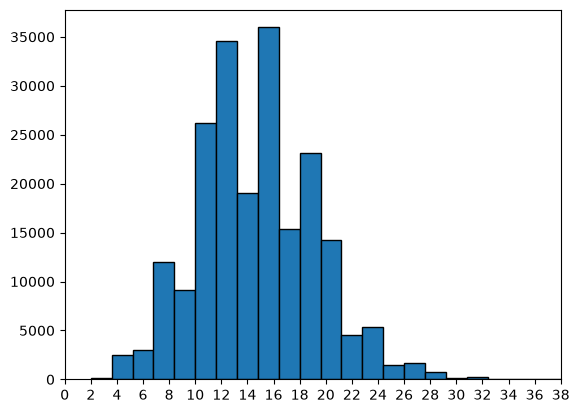

In [ ]:
#this is a plot of tokens which will be used to determine max length in the bert model from graph we can say that max length,which can 
#of the size 32 .
plt.hist(news_data["token_length"], bins=80,edgecolor="black")
plt.xlim(0,30)
plt.xticks(np.arange(0,40,2))
plt.show()

In [62]:
news_data["token_length"].max()
print("95th percentile:", np.percentile(news_data["token_length"], 95))
print("99th percentile:", np.percentile(news_data["token_length"], 99))

95th percentile: 22.0
99th percentile: 26.0


In [52]:
news_data.head()

,headline,category,headline_length,token_length
0,Over 4 Million Americans Roll Up Sleeves For O...,U.S. NEWS,11,19
1,"American Airlines Flyer Charged, Banned For Li...",U.S. NEWS,13,16
2,23 Of The Funniest Tweets About Cats And Dogs ...,COMEDY,13,24
3,The Funniest Tweets From Parents This Week (Se...,PARENTING,9,20
4,Woman Who Called Cops On Black Bird-Watcher Lo...,U.S. NEWS,11,18


In [63]:
#Split the data as headline and category
x=news_data["headline"]
y=news_data["category"]

In [64]:
#now split the data int0 testing set and training set
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [93]:
from transformers import AutoTokenizer

tokenizer=AutoTokenizer.from_pretrained("bert-base-uncased")

train_encodings=tokenizer(
    list(x_train),
    truncation=True,
    padding=True,
    max_length=32,
    return_tensors="pt"
)

test_encodings=tokenizer(
    list(x_test),
    truncation=True,
    padding=True,
    max_length=32,
    return_tensors="pt"
)

In [94]:
#in the above cell we converted our testing and training data into tokens and returned them as tensors which will be ready for bert 
#based model to feed in
from sklearn.preprocessing import LabelEncoder
encoder=LabelEncoder()
y_train=encoder.fit_transform(y_train)
y_test=encoder.transform(y_test)

In [95]:
import torch
from torch.utils.data import Dataset

In [96]:
class NewsDataset(Dataset):
    def __init__(self,encodings,labels):
        self.encodings=encodings
        self.labels=labels
    def __getitem__(self,idx):
        item={}

        for key,value in self.encodings.items():
            item[key]=value[idx]

        item["labels"]=torch.tensor(self.labels[idx])

        return item
    
    def __len__(self):
        return len(self.labels)

In [97]:
#creating dataset objects
train_dataset=NewsDataset(train_encodings,y_train)
test_dataset=NewsDataset(test_encodings,y_test)

In [98]:
print(train_dataset[0])

{'input_ids': tensor([  101,  1996,  2572,  5638, 17479,  5897,  1997,  2019, 26855,   102,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
            0,     0]), 'token_type_ids': tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0]), 'attention_mask': tensor([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0, 0, 0]), 'labels': tensor(16)}


In [99]:
#Now create Dataloaders they send the data into the model in mini-batches
from torch.utils.data import DataLoader

train_loader=DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

test_loader=DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)

In [100]:
#Loading the BERT model 
from transformers import AutoModelForSequenceClassification

model=AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased",
    num_labels=len(encoder.classes_)
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [101]:
#Moving the model to GPU
import torch

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [102]:
#defining the optimizer which is used for updating weights after every batch to reduce the loss
from torch.optim import AdamW

optimizer=AdamW(
    model.parameters(),
    lr=2e-5
)

In [103]:
#A scheduler controls how the learning rate changes during trainingno
from transformers import get_scheduler

num_epochs=3

num_training_steps=num_epochs*len(train_loader)

lr_scheduler=get_scheduler(
    "linear",
    optimizer=optimizer,
    num_warmup_steps=0,
    num_training_steps=num_training_steps
)

In [104]:
model.train()#druring training some layers like dropout should be active,during testing they should be disabled so before training always write this

for epoch in range(num_epochs):
    total_loss=0
    for batch in train_loader:
        batch={k: v.to(device) for k,v in batch.items()}

        optimizer.zero_grad()

        outputs=model(**batch)

        loss=outputs.loss

        loss.backward()

        optimizer.step()

        lr_scheduler.step()

        total_loss+=loss.item()

    avg_loss=total_loss/len(train_loader)

    print(f"Epoch {epoch+1}:Loss={avg_loss:.4f}")

Epoch 1:Loss=1.4918
Epoch 2:Loss=1.0476
Epoch 3:Loss=0.8168


In [ ]:
#Evaluating the model
model.eval()

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,),

In [ ]:
all_predictions = []
all_labels = [] 

In [ ]:
#disabling the gradient computation because it is essential for model inference,validation and testing
#because it drastically reduces memory consumption and accelerates computations by preventing the framework
#from building unnecessary backpropagation graphs
import torch

with torch.no_grad():

    for batch in test_loader:

        batch={k:v.to(device) for k,v in batch.items()}

        outputs= model(
            input_ids=batch["input_ids"],
            attention_mask=batch["attention_mask"]
        )

        logits=outputs.logits
        predictions=torch.argmax(logits,dim=1)
        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(batch["labels"].cpu().numpy())

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
accuracy = accuracy_score(all_labels, all_predictions)
print("Accuracy:", accuracy)
precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.6570889912416772
Precision: 0.6490699426598466
Recall: 0.6570889912416772
F1 Score: 0.6501112221850822


In [114]:
print(classification_report(all_labels, all_predictions))

              precision    recall  f1-score   support

           0       0.40      0.33      0.36       302
           1       0.42      0.36      0.39       268
           2       0.55      0.50      0.52       917
           3       0.55      0.52      0.53      1198
           4       0.54      0.52      0.53       229
           5       0.60      0.52      0.56      1080
           6       0.63      0.66      0.64       712
           7       0.66      0.32      0.43       215
           8       0.78      0.74      0.76       685
           9       0.48      0.45      0.46       203
          10       0.73      0.79      0.76      3473
          11       0.62      0.33      0.43       289
          12       0.46      0.28      0.35       280
          13       0.72      0.76      0.74      1268
          14       0.47      0.38      0.42       280
          15       0.42      0.53      0.47       524
          16       0.40      0.32      0.36      1339
          17       0.79    

In [116]:
cm = confusion_matrix(all_labels, all_predictions)
cm_normalized = cm.astype("float") / cm.sum(axis=1, keepdims=True)

print(cm)

[[100  40   7 ...   2   0   4]
 [ 24  97  14 ...   8   0   0]
 [  4   3 457 ...   7   2   1]
 ...
 [  2   8   5 ... 284   6   0]
 [  2   1   3 ...   4 245  44]
 [  4   1   0 ...   2  41 158]]


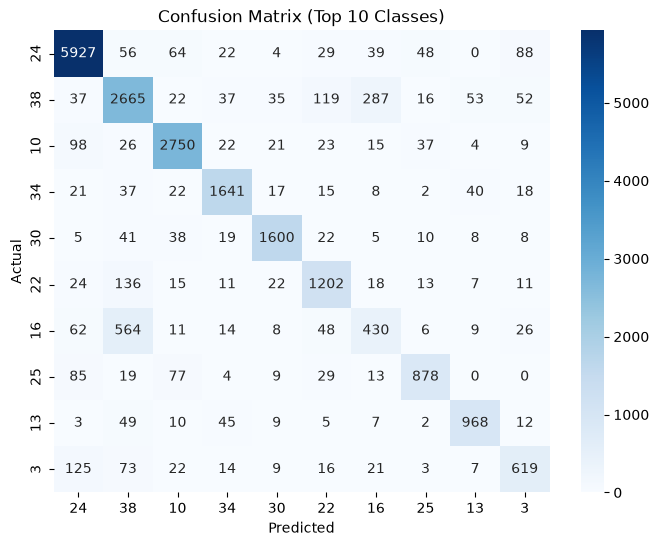

In [ ]:
#from the below confusion matrix we can understand that model is predicting mistakes between classes between
#categories 16 and 38
top_classes = pd.Series(all_labels).value_counts().nlargest(10).index

cm_top = confusion_matrix(
    all_labels,
    all_predictions,
    labels=top_classes
)

plt.figure(figsize=(8,6))

sns.heatmap(
    cm_top,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=top_classes,
    yticklabels=top_classes
)

plt.title("Confusion Matrix (Top 10 Classes)")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [ ]:
#save the model
model.save_pretrained("bert_news_classifier")
tokenizer.save_pretrained("bert_news_classifier")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('bert_news_classifier\\tokenizer_config.json',
 'bert_news_classifier\\tokenizer.json')

In [ ]:
#this cell converts numbers with categories that humans can understand
from sklearn.preprocessing import LabelEncoder

category_encoder = LabelEncoder()

category_encoder.fit(news_data["category"])

Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)Holds the label for each class.","ndarray[object](42,)","['ARTS','ARTS & CULTURE','BLACK VOICES',...,'WOMEN','WORLD NEWS', 'WORLDPOST']"


In [ ]:
#this is the prediction function which is used for analysing our results 
import torch
import torch.nn.functional as F

def predict_top3(headline):

    encoding = tokenizer(
        headline,
        truncation=True,
        padding=True,
        max_length=32,
        return_tensors="pt"
    )

    encoding = {k: v.to(device) for k, v in encoding.items()}

    model.eval()

    with torch.no_grad():
        outputs = model(**encoding)

    probs = F.softmax(outputs.logits, dim=1)

    top_probs, top_classes = torch.topk(probs, k=3)

    print(f"\nHeadline:\n{headline}\n")
    print("Top 3 Predictions:\n")

    for prob, cls in zip(top_probs[0], top_classes[0]):
        print(
            f"{category_encoder.classes_[cls.item()]:<20} {prob.item()*100:.2f}%"
        )

In [141]:
predict_top3("Apple unveils its latest AI-powered iPhone with advanced camera features")
predict_top3("India defeated Australia by six wickets in the ODI series")
predict_top3("Stock markets rallied after the central bank announced lower interest rates")
predict_top3("The latest Marvel movie broke box office records during its opening weekend")
predict_top3("The government introduced a new education policy in Parliament today")
predict_top3("NASA successfully launched a new satellite to study climate change")
predict_top3("Raj shamani is india's greatest football player")


Headline:
Apple unveils its latest AI-powered iPhone with advanced camera features

Top 3 Predictions:

TECH                 96.60%
BUSINESS             0.79%
WORLD NEWS           0.35%

Headline:
India defeated Australia by six wickets in the ODI series

Top 3 Predictions:

SPORTS               84.44%
WORLD NEWS           5.34%
THE WORLDPOST        2.10%

Headline:
Stock markets rallied after the central bank announced lower interest rates

Top 3 Predictions:

BUSINESS             84.14%
MONEY                7.45%
POLITICS             6.20%

Headline:
The latest Marvel movie broke box office records during its opening weekend

Top 3 Predictions:

ENTERTAINMENT        99.47%
ARTS & CULTURE       0.08%
STYLE                0.08%

Headline:
The government introduced a new education policy in Parliament today

Top 3 Predictions:

EDUCATION            50.33%
POLITICS             23.98%
IMPACT               5.91%

Headline:
NASA successfully launched a new satellite to study climate change

In [ ]:
#these are the final results of our BERT based model which is used for news category prediction